In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction import image
from sklearn.decomposition import DictionaryLearning
import cv2

# -----------------------------
# 1. Load image (convert to grayscale)
# -----------------------------
img = cv2.imread("var.jpeg")
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64) / 255.0

# -----------------------------
# 2. Extract patches (signals)
# -----------------------------
patch_size = (8, 8)

patches = image.extract_patches_2d(img_gray, patch_size)
n_patches = patches.shape[0]
print(f"Extracted {n_patches} patches of size {patch_size}.")

# flatten patches → 64-dim vectors
X = patches.reshape(n_patches, -1)

# center each patch (zero mean — important for learning edges)
X -= np.mean(X, axis=1, keepdims=True)

# normalize variance so dictionary learning converges better
X /= (np.std(X, axis=1, keepdims=True) + 1e-6)

# subsample if too many patches (speeds up fitting significantly)
max_patches = 10000
if X.shape[0] > max_patches:
    rng = np.random.RandomState(0)
    idx = rng.choice(X.shape[0], max_patches, replace=False)
    X = X[idx]

# -----------------------------
# 3. Dictionary Learning
# -----------------------------
n_atoms = 64

dict_learner = DictionaryLearning(
    n_components=n_atoms,
    alpha=1,        # sparsity (higher = more edge-like)
    max_iter=15,
    random_state=0
)

A = dict_learner.fit_transform(X)
D = dict_learner.components_



Extracted 47360 patches of size (8, 8).


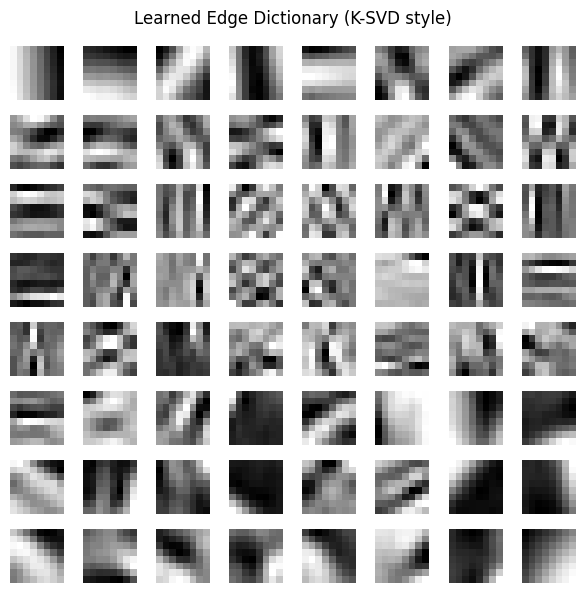

In [3]:
# -----------------------------
# 4. Visualize learned dictionary atoms
# -----------------------------
def plot_dictionary(D):
    plt.figure(figsize=(6, 6))

    for i in range(min(64, D.shape[0])):
        plt.subplot(8, 8, i + 1)
        plt.imshow(D[i].reshape(8, 8), cmap='gray')
        plt.axis('off')

    plt.suptitle("Learned Edge Dictionary (K-SVD style)")
    plt.tight_layout()
    plt.show()

plot_dictionary(D)

In [4]:
print("Learned dictionary shape:", D.shape)

Learned dictionary shape: (64, 64)
